<a href="https://colab.research.google.com/github/afrin7427-prog/Tomato-Leaf-Disease-CNN/blob/main/finalassignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np
import os, zipfile, random

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

torch.manual_seed(0)
np.random.seed(0)
random.seed(0)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


Using device: cpu


In [ ]:

from google.colab import files
uploaded = files.upload()

zip_name = next(iter(uploaded.keys()))
extract_path = '/content/tomato_dataset'
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted to:", extract_path)

Saving Dataset-20260405T145315Z-3-001.zip to Dataset-20260405T145315Z-3-001 (1).zip
Dataset extracted to: /content/tomato_dataset


In [ ]:
def find_split_folder(root, possible_names):
    for current_root, dirs, files_in_dir in os.walk(root):
        folder_name = os.path.basename(current_root).lower()
        if folder_name in possible_names:

            class_folders = [
                d for d in dirs
                if os.path.isdir(os.path.join(current_root, d))
            ]
            if len(class_folders) >= 2:
                return current_root
    return None

train_folder = find_split_folder(extract_path, {'train', 'training', 'train_set'})
val_folder   = find_split_folder(extract_path, {'val', 'valid', 'validation', 'val_set'})
test_folder  = find_split_folder(extract_path, {'test', 'testing', 'test_set'})

print("Train folder:", train_folder)
print("Validation folder:", val_folder)
print("Test folder:", test_folder)

if not all([train_folder, val_folder, test_folder]):
    raise FileNotFoundError(
        "Could not find all train/val/test folders. "
        "Check the extracted ZIP folder structure."
    )

print("\nTrain classes:", os.listdir(train_folder))
print("Validation classes:", os.listdir(val_folder))
print("Test classes:", os.listdir(test_folder))

Train folder: /content/tomato_dataset/Dataset/train
Validation folder: /content/tomato_dataset/Dataset/val
Test folder: /content/tomato_dataset/Dataset/test

Train classes: ['Tomato___Late_blight', 'Tomato___Early_blight', 'Tomato___Leaf_Mold', 'Tomato___Bacterial_spot', 'Tomato___Septoria_leaf_spot', 'Tomato___healthy']
Validation classes: ['Tomato___Late_blight', 'Tomato___Early_blight', 'Tomato___Leaf_Mold', 'Tomato___Bacterial_spot', 'Tomato___Septoria_leaf_spot', 'Tomato___healthy']
Test classes: ['Tomato___Late_blight', 'Tomato___Early_blight', 'Tomato___Leaf_Mold', 'Tomato___Bacterial_spot', 'Tomato___Septoria_leaf_spot', 'Tomato___healthy']


In [ ]:
IMG_SIZE = 128

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

In [ ]:
train_data = datasets.ImageFolder(train_folder, transform=train_transform)
val_data   = datasets.ImageFolder(val_folder, transform=test_transform)
test_data  = datasets.ImageFolder(test_folder, transform=test_transform)

class_names = train_data.classes
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)
print("Train images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))

assert train_data.class_to_idx == val_data.class_to_idx == test_data.class_to_idx, \
    "Class folders/order differ between train, validation and test!"

Classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___healthy']
Number of classes: 6
Train images: 4586
Validation images: 981
Test images: 990


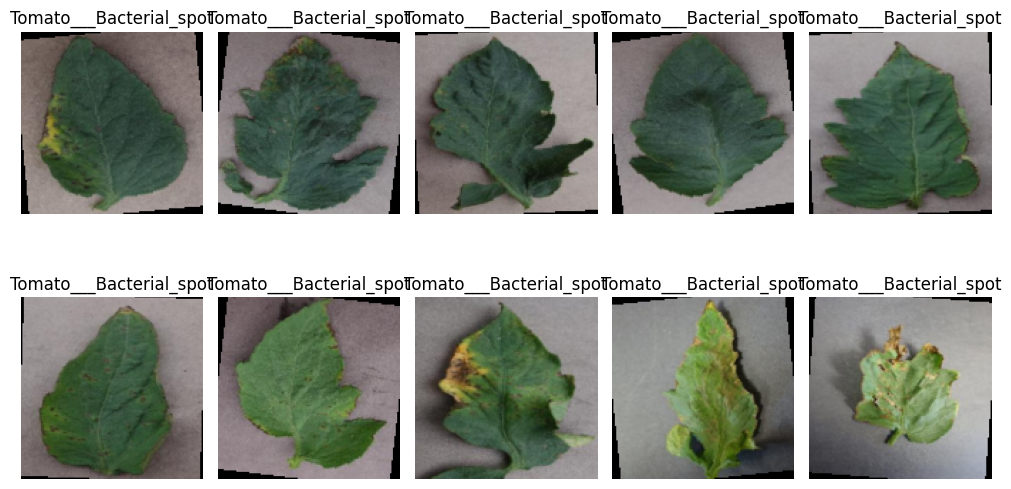

In [ ]:
plt.figure(figsize=(10, 6))

for i in range(min(10, len(train_data))):
    img, label = train_data[i]

    img = img * 0.5 + 0.5

    plt.subplot(2, 5, i + 1)
    plt.imshow(img.permute(1, 2, 0))
    plt.title(class_names[label])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
batch_size = 32
learning_rate = 0.001
epochs = 20

train_loader = DataLoader(
    train_data, batch_size=batch_size, shuffle=True,
    num_workers=2, pin_memory=(device.type == 'cuda')
)

val_loader = DataLoader(
    val_data, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=(device.type == 'cuda')
)

test_loader = DataLoader(
    test_data, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=(device.type == 'cuda')
)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)
loss_fn = nn.CrossEntropyLoss()

In [44]:
class CNNModel(nn.Module):
    def __init__(self, num_classes):
        super(CNNModel, self).__init__()

        self.conv_layers = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 14 * 14, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

model = CNNModel(num_classes=num_classes).to(device)
print(model)
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total Trainable Parameters:", total_params)

CNNModel(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=25088, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=6, bias=True)
  )
)
Total Trainable Parameters: 6517574


In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [ ]:
def train_epoch(model, loader, optimizer, loss_fn, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / len(loader), correct / total


def evaluate_epoch(model, loader, loss_fn, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = loss_fn(outputs, labels)

            total_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return total_loss / len(loader), correct / total

In [ ]:
epochs = 20

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for ep in range(epochs):

    train_loss, train_acc = train_epoch(
        model, train_loader, optimizer, loss_fn, device
    )

    val_loss, val_acc = evaluate_epoch(
        model, val_loader, loss_fn, device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print("----------------------------------------------")
    print(f"Epoch {ep+1}/{epochs}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f}")


----------------------------------------------
Epoch 1/20
Train Loss: 1.0871 | Train Acc: 0.5733
Val Loss:   0.5892 | Val Acc:   0.7666
----------------------------------------------
Epoch 2/20
Train Loss: 0.6213 | Train Acc: 0.7671
Val Loss:   0.4080 | Val Acc:   0.8491
----------------------------------------------
Epoch 3/20
Train Loss: 0.4908 | Train Acc: 0.8201
Val Loss:   0.3433 | Val Acc:   0.8838
----------------------------------------------
Epoch 4/20
Train Loss: 0.4082 | Train Acc: 0.8548
Val Loss:   0.3183 | Val Acc:   0.8879
----------------------------------------------
Epoch 5/20
Train Loss: 0.3360 | Train Acc: 0.8875
Val Loss:   0.2513 | Val Acc:   0.9032
----------------------------------------------
Epoch 6/20
Train Loss: 0.2847 | Train Acc: 0.8997
Val Loss:   0.2975 | Val Acc:   0.8889
----------------------------------------------
Epoch 7/20
Train Loss: 0.2766 | Train Acc: 0.9051
Val Loss:   0.1979 | Val Acc:   0.9246
----------------------------------------------
E

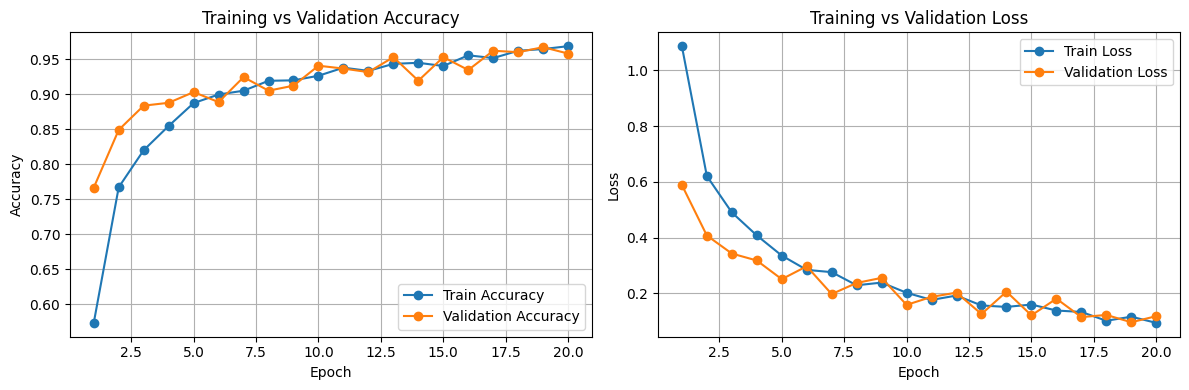

In [ ]:
epochs_number = range(1, len(train_accuracies) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_number, train_accuracies, marker='o', label='Train Accuracy')
plt.plot(epochs_number, val_accuracies, marker='o', label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_number, train_losses, marker='o', label='Train Loss')
plt.plot(epochs_number, val_losses, marker='o', label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_acc = evaluate_epoch(model, test_loader, loss_fn, device)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Test Loss: 0.1602
Test Accuracy: 95.05%


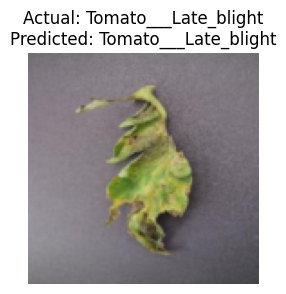

In [ ]:
model.eval()

img, actual_label = test_data[465]
x = img.unsqueeze(0).to(device)

with torch.no_grad():
    output = model(x)
    predicted_label = torch.argmax(output, dim=1).item()
img = img * 0.5 + 0.5
plt.figure(figsize=(3, 3))
plt.imshow(img.permute(1, 2, 0))
plt.title(
    f"Actual: {class_names[actual_label]}\n"
    f"Predicted: {class_names[predicted_label]}"
)
plt.axis('off')
plt.show()

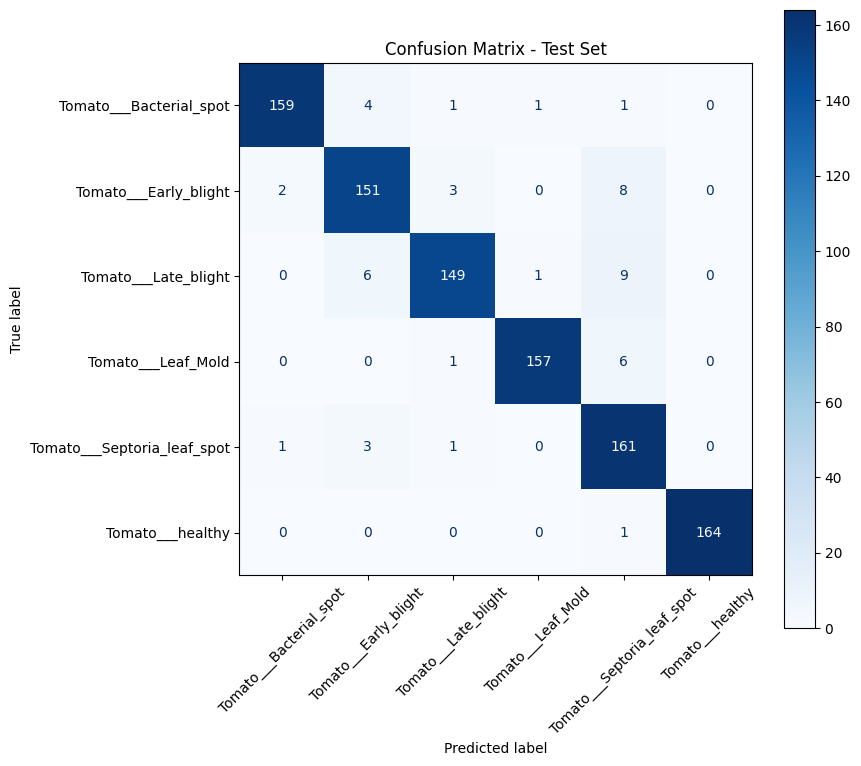

In [ ]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
fig, ax = plt.subplots(figsize=(9, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax, xticks_rotation=45)
plt.title('Confusion Matrix - Test Set')
plt.tight_layout()
plt.show()

In [ ]:
torch.save(model.state_dict(), 'tomato_leaf_cnn.pth')
print("Model saved successfully!")

Model saved successfully!
